In [7]:
# requires:
# conda install -c conda-forge gdal
# conda install -c conda-forge libgdal-hdf4
# conda install rasterio                      <--- needs to be the conda version; pip version has only minimal GDAL and can't open HDF files

import os
from functools import lru_cache
import glob
import json
import numpy as np
import pandas as pd

import rasterio
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.merge import merge
from rasterio.windows import from_bounds

import torch
from torch.utils.data import Dataset, DataLoader

In [8]:
from io import StringIO
import re

with open("sn_bound_10deg.txt") as f:
    raw = f.read()
lines = [ln for ln in raw.splitlines()
         if ln.strip() and re.match(r"^\d", ln.strip())]
buf = StringIO("\n".join(lines))
cols = ["iv", "ih", "lon_min", "lon_max", "lat_min", "lat_max"]
modis_grid = pd.read_csv(buf, delim_whitespace=True, header=None, names=cols)

def lat_lon_to_modis(ctr_lat, ctr_long):
    rows = modis_grid[ (modis_grid.lon_min <= ctr_long) & ( ctr_long <= modis_grid.lon_max) & (modis_grid.lat_min <= ctr_lat) & ( ctr_lat <= modis_grid.lat_max) ]
    return list(zip(rows.ih.values, rows.iv.values))

/tmp/ipykernel_2865966/851350310.py:10: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  modis_grid = pd.read_csv(buf, delim_whitespace=True, header=None, names=cols)


In [9]:
study = '5a280544-06db-4c85-9713-842547972edd' # '338388ea-6483-472c-9cdc-c2997e645df0'

# reproduce (brittle) logic in gee_chips_v2
df = pd.read_csv(glob.glob(f'mbr_studies_2year_filtered_traintest/{study}*')[0])
df = df[df.set == 'train']
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df = df.dropna(subset=['timestamp'])

In [36]:
### rasterio methods ###

def _get_rasterio(path):
    with rasterio.open(path) as ds:
        arr = ds.read()
        return {
                    "array": arr,
                    "transform": ds.transform,
                    "crs": ds.crs,
                    "nodata": ds.nodata,
                    "bounds": ds.bounds,
                    "bands": ds.descriptions
                }

@lru_cache(maxsize=16)
def _get_rasterio_cached(path):
    return _get_rasterio(path)

@lru_cache(maxsize=20)
def _get_rasterio_window_cached(path, bounds):
    with rasterio.open(path) as ds:
        min_lon, min_lat, max_lon, max_lat = bounds
        window = from_bounds(min_lon, min_lat, max_lon, max_lat, ds.transform)
        return {
            "array": ds.read(window=window),
            "transform": ds.window_transform(window),
            "crs": ds.crs,
            "nodata": ds.nodata,
            "bounds": bounds, # rasterio.windows.bounds(window, ds.transform),
        }

@lru_cache(maxsize=20)
def _get_merged_rasterio_window_cached(paths, bounds_latlon):
    """Applies CRF bounds transform (to accomodate MODIS)
    """
    datasets = [rasterio.open(p) for p in paths]
    try:
        crs = datasets[0].crs
        descriptions = datasets[0].descriptions
        nodata_val = datasets[0].nodata or 255

        # transform to MODIS CRS
        left, bottom, right, top = transform_bounds(
            "EPSG:4326", # bounds assumed to come from EPSG:4326
            crs,         # but we want to use them in the target (e.g. MODIS) CRS
            *bounds_latlon,
        )

        mosaic, out_transform = merge(
            datasets,
            bounds=(left, bottom, right, top),
            nodata=nodata_val,
            resampling=rasterio.enums.Resampling.nearest,
        )
    except:
        print("Oh no! In _get_merged_rasterio_window_cached")
    finally:
        for ds in datasets:
            ds.close()

    return {
        "array": mosaic,           # (bands, H, W)
        "transform": out_transform,
        "crs": crs,
        "nodata": nodata_val,
        "bounds": (left, bottom, right, top),
        "bands": descriptions,
    }

def _reproject_all(layers):
    """Return all layers reprojected as float32."""
    ref_raster = layers[0]
    _, H_ref, W_ref = ref_raster['array'].shape
    
    aligned = [ ref_raster['array'] ]
    dst_crs = ref_raster['crs']
    dst_transform = ref_raster['transform']
    for layer in layers[1:]:
        # create new np array as destination - same channels as this layer but with target width/height
        dst = np.full((layer["array"].shape[0], H_ref, W_ref), np.nan, dtype=np.float32)
        reproject(
            source=layer["array"], # (C, H_src, W_src)
            destination=dst,
            src_transform=layer["transform"],
            src_crs=layer["crs"],
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            resampling=Resampling.nearest,   # nearest or bilinear
        )
        aligned.append(dst)

    return aligned

from rasterio.warp import reproject, calculate_default_transform
from rasterio.transform import array_bounds
from rasterio.enums import Resampling


def _reproject_all_to_meters(layers, dst_crs="EPSG:3857"):
    ref_raster = layers[0]
    _, H_ref, W_ref = ref_raster['array'].shape

    # compute transform/shape in metric CRS
    dst_transform, dst_width, dst_height = calculate_default_transform(
        ref_raster["crs"],     # source CRS (lat/lon)
        dst_crs,               # target CRS (meters)
        W_ref, H_ref,
        *ref_raster['bounds'], # in ref_raster["crs"]
    )

    aligned = []
    for layer in layers:
        C = layer["array"].shape[0]
        dst = np.full((C, dst_height, dst_width), np.nan, dtype=np.float32)

        reproject(
            source=layer["array"],
            destination=dst,
            src_transform=layer["transform"],
            src_crs=layer["crs"],
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            resampling=Resampling.nearest,
        )
        aligned.append(dst)

    return aligned #, dst_transform, dst_crs


In [37]:
class ChipDataset(Dataset):
    def __init__(self,  study_id, idx_to_timestamp, chip_base_dir='chips_out', dem_base_dir='dem_out'):
        self.idx_to_timestamp = idx_to_timestamp.reset_index() # reset index to allow easy iteration but retain old index

        self.chip_dir = os.path.join(chip_base_dir, study_id)
        self.dem_dir  = os.path.join(dem_base_dir, study_id)
        self.dem_manifest = json.load(open(os.path.join(self.dem_dir, 'dem_manifest.json'), 'r'))

        self.hii_dir = '/archive/vision/beery/movebench/human_impact_index/'
        self.cvf_dir = '/archive/vision/beery/movebench/modis_cvf2015-2025/'
        self.lc_dir = '/archive/vision/beery/movebench/modis_lc2015-2025/'
        self.bioclim_dir = '/archive/vision/beery/movebench/bioclim/'

        # build modis filepath indices to avoid globs later
        # self.lc_dir + f"/MCD12Q1.A{year}001.h{h:02d}v{v:02d}*.hdf"
        self.modis_lc_index = {}
        for path in glob.glob(self.lc_dir + "/MCD12Q1.A*.h*v*.hdf"):
            fname = os.path.basename(path)
            year = int(fname.split(".A")[1][:4])
            h = int(fname.split(".h")[1][:2])
            v = int(fname.split("v")[1][:2])
            self.modis_lc_index[(int(year), int(h), int(v))] = path
        
        self.modis_cvf_index = {}
        for path in glob.glob(self.cvf_dir + "/MOD44B.A*.h*v*.hdf"):
            fname = os.path.basename(path)
            year = int(fname.split(".A")[1][:4])
            h = int(fname.split(".h")[1][:2])
            v = int(fname.split("v")[1][:2])
            self.modis_cvf_index[(int(year), int(h), int(v))] = path

        # TODO figure out where to cache these long term
        self.mean, self.std = None, None
        if os.path.exists(f'{study}_mean.pt'):
            self.mean = torch.load(f'{study}_mean.pt')
            self.std  = torch.load(f'{study}_std.pt')
        else:
            print("WARNING: Features will not be standardized for", study)

    def __getitem__(self, idx):
        idx, timestamp = self.idx_to_timestamp.iloc[idx].values # map to original df index
        idx = int(idx)
        all_layers = []
        layer_names = []
        
        # ERA5 chips
        big_chip   = _get_rasterio(os.path.join(self.chip_dir, f"point_{idx}_big.tif"))
        med_chip   = _get_rasterio(os.path.join(self.chip_dir, f"point_{idx}_medium.tif"))
        # print("big:", big_chip['array'].shape)
        # print("med:", med_chip['array'].shape)
        # right now, small is just dynamic world, and it's broken
        # small_chip = _get_rasterio(os.path.join(self.chip_dir, f"point_{idx}_small.tif"))
        all_layers.extend([med_chip, big_chip])
        layer_names.extend(["era5_med", "era5_big"]) # TODO: would need med_bands, big_bands to access these later for e.g. derived features

        # get location for other queries -- assume small will be the most accurate
        bounds = med_chip['bounds']
        center_lon = (bounds[0] + bounds[2]) / 2
        center_lat = (bounds[1] + bounds[3]) / 2

        # DEM - bigger tile
        for chunk in self.dem_manifest.get("chunk_info", []):
            b = chunk["bounds"]
            if b["min_lon"] <= center_lon <= b["max_lon"] and b["min_lat"] <= center_lat <= b["max_lat"]:
                demf = os.path.join(self.dem_dir, chunk["filename"])
                dem_raster = _get_rasterio_cached(demf)
                # dem_raster = _get_rasterio_window_cached(demf, med_chip['bounds'])
                break
        # print("DEM", dem_raster['array'].shape)
        all_layers.append(dem_raster)
        layer_names.append("DEM")
        
        # MODIS land cover -- annual, hdf files
        # int-valued (should be one-hot as features)
        year = int(max(min(timestamp.year, 2025), 2015))
        # get all files that the bounds fall into - will need to merge them
        hvs = []
        for lat in [ bounds[1], bounds[3] ]:
            for lon in [ bounds[0], bounds[2] ]:
                hvs.extend(lat_lon_to_modis(lat, lon))
        sd_paths = []
        for (h, v) in hvs:
            hdf_path_i = self.modis_lc_index[(year, int(h), int(v))]
            sd_paths.append("HDF4_EOS:EOS_GRID:" + hdf_path_i + ":MCD12Q1:LC_Type1")
        lc_raster = _get_merged_rasterio_window_cached(tuple(sd_paths), bounds)
        # print("MODIS LC", lc_raster['array'].shape)
        all_layers.append(lc_raster)
        layer_names.append("modis_lc")
        
        # MODIS vegetation cover -- annual
        cvf_rasters = []
        for band in [':MOD44B_250m_GRID:Percent_Tree_Cover', 
                     ':MOD44B_250m_GRID:Percent_NonTree_Vegetation',
                     ':MOD44B_250m_GRID:Percent_NonVegetated']:
            sd_paths = []
            for (h, v) in hvs:
                hdf_path_i = self.modis_cvf_index[(year, int(h), int(v))]
                sd_paths.append("HDF4_EOS:EOS_GRID:" + hdf_path_i + band)
            # print("merging", sd_paths)
            cvf_raster = _get_merged_rasterio_window_cached(tuple(sd_paths), bounds)
            cvf_rasters.append(cvf_raster)
        # print("MODIS CVF", [cvf_raster['array'].shape for cvf_raster in cvf_rasters])
        all_layers.extend(cvf_rasters)
        layer_names.extend(["modis_treecover", "modis_nontreeveg", "modis_nonveg"])

        # Human impact -- annual
        year = max(min(timestamp.year, 2020), 2015)
        hii_f = os.path.join(self.hii_dir, f'hii_{year}-01-01.tif')
        hii_raster = _get_rasterio_window_cached(hii_f, med_chip['bounds'])
        # print("HII", hii_raster['array'].shape)
        all_layers.append(hii_raster)
        layer_names.append("HII")

        # BioClim -- no time; whole world
        bioclim_fs = [ os.path.join(self.bioclim_dir, f"wc2.1_30s_bio_{i}.tif") for i in range(1,20) ] 
        bioclim_rasters = [ _get_rasterio_window_cached(bioclim_f, med_chip['bounds']) for bioclim_f in bioclim_fs ]
        # print("bioclim", [raster['array'].shape for raster in bioclim_rasters])
        all_layers.extend(bioclim_rasters)
        layer_names.extend([ f"bioclim_{i}" for i in range(1,20) ])

        # reproject all to same resolution/CRS/bounds
        # and convert to torch
        # TODO project to meters, not lat/long
        # reprojected = _reproject_all(all_layers)
        reprojected = _reproject_all_to_meters(all_layers)
        reprojected_t =[
            torch.from_numpy(l) for l in reprojected
        ]

        # TODO add derived types - e.g. uplift
        # ...later...

        # convert classification data to one-hot
        lc_idx = layer_names.index("modis_lc")
        lc_nc  = 18 # should be 17 classes in modis land cover, but sometimes there are 0 vals
        reprojected_t[lc_idx][reprojected_t[lc_idx] > 17] = 0 # make any invalid entries 0
        reprojected_t[lc_idx] = torch.nn.functional.one_hot(reprojected_t[lc_idx].long(), 
                                                            num_classes=lc_nc).squeeze(0).permute(2,0,1)
        
        # compute the nodata mask
        nodata_vals  = [ a['nodata'] or torch.inf for a in all_layers ] # need to 'or' to catch None values, which mess up the equality test
        valid_masks  = [ (layer != nodata_val) for layer, nodata_val in zip(reprojected_t, nodata_vals) ]

        # concat and standardize columns if appropriate
        final_t = torch.cat(reprojected_t)
        lc_start_idx = sum([ a['array'].shape[0] for a in all_layers[:lc_idx] ])
        if self.mean is not None:
            norm_mask = torch.ones(final_t.shape[0], dtype=bool)
            norm_mask[lc_start_idx:lc_start_idx+lc_nc] = False
            normed = (final_t - self.mean[:, None, None]) / self.std[:, None, None]
            final_t = torch.where(norm_mask[:, None, None], normed, final_t)

        return final_t, torch.cat(valid_masks)

    def __len__(self):
        return len(self.idx_to_timestamp)

In [39]:
# import time
ds = ChipDataset(study, idx_to_timestamp=pd.to_datetime(df.timestamp))
ds[393][0].shape

torch.Size([63, 79, 77])

In [6]:
from tqdm import tqdm

dataloader = DataLoader(ds, 
                        batch_size=1,
                        shuffle=False, 
                        num_workers=16)

# get values for standardization
layer_sum = None
layer_sq_sum = None
count = None
for i_batch, (x, valid_mask) in tqdm(enumerate(dataloader), total=len(ds)):
    x = x.squeeze(0)
    valid_mask = valid_mask.squeeze(0)
    num_valid  = valid_mask.sum(dim=(-1, -2))  # (C,)
    x_clean = torch.where(valid_mask, x, torch.zeros_like(x))

    # Per-layer sums
    s  = x_clean.sum(dim=(-1, -2))         # (C,)
    s2 = (x_clean ** 2).sum(dim=(-1, -2))  # (C,)

    if layer_sum is None:
        layer_sum = s
        layer_sq_sum = s2
        count = num_valid
    else:
        layer_sum += s
        layer_sq_sum += s2
        count += num_valid

print("Done")

mean = layer_sum / count
var  = layer_sq_sum / count - mean**2
var = torch.clamp(var, min=0.0)
std = torch.sqrt(var)

torch.save(mean, f'{study}_mean.pt')
torch.save(std,  f'{study}_std.pt')

NameError: name 'ds' is not defined

In [ ]:
## Standardization ##
## TODO: Subsample ~1000 randomly per study ##

studies = [ d for d in os.listdir('dem_out') if os.path.isdir('dem_out/'+d) ]
studies.remove('c73c7698-2c6b-44d4-8879-fe10d7536935') # this one failed

for study in studies:
    if os.path.exists(f'{study}_mean.pt'):
        print("Already computed", study)
    else:
        print("Getting standardization values for", study)

        df = pd.read_csv(glob.glob(f'mbr_studies_2year_filtered_traintest/{study}*')[0])
        df = df[df.set == 'train']
        df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
        df = df.dropna(subset=['timestamp'])
        
        ds = ChipDataset(study, idx_to_timestamp=pd.to_datetime(df.timestamp))
        dataloader = DataLoader(ds, 
                        batch_size=1,
                        shuffle=False, 
                        num_workers=16)

        # get values for standardization
        layer_sum = None
        layer_sq_sum = None
        count = None
        for i_batch, (x, valid_mask) in tqdm(enumerate(dataloader), total=len(ds)):
            x = x.squeeze(0)
            valid_mask = valid_mask.squeeze(0)
            num_valid  = valid_mask.sum(dim=(-1, -2))  # (C,)
            x_clean = torch.where(valid_mask, x, torch.zeros_like(x))

            # Per-layer sums
            s  = x_clean.sum(dim=(-1, -2))         # (C,)
            s2 = (x_clean ** 2).sum(dim=(-1, -2))  # (C,)

            if layer_sum is None:
                layer_sum = s
                layer_sq_sum = s2
                count = num_valid
            else:
                layer_sum += s
                layer_sq_sum += s2
                count += num_valid

        print("Done")

        mean = layer_sum / count
        var  = layer_sq_sum / count - mean**2
        var = torch.clamp(var, min=0.0)
        std = torch.sqrt(var)

        torch.save(mean, f'{study}_mean.pt')
        torch.save(std,  f'{study}_std.pt')

        print("Saved", study)

Getting standardization values for fd28aac2-b22f-4368-8638-59906e769ded


/data/vision/beery/scratch/justin/envs/movement/lib/python3.11/site-packages/torch/utils/data/dataloader.py:626: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 8, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
  0%|          | 0/4088 [00:01<?, ?it/s]


KeyboardInterrupt: 

----

SSF

In [79]:
from shapely import Point
import numpy as np
import math


def _bearing(a: Point, b: Point) -> float:
    return np.arctan2(b.y - a.y, b.x - a.x)

def _step_len(a: Point, b: Point) -> float:
    return a.distance(b)

def haversine(lat1, lon1, lat2, lon2):
    R = 6371000  # Earth radius in meters

    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)

    a = math.sin(dphi/2)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda/2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

    return R * c  # distance in meters


class SSFDataset(ChipDataset):
    def __init__(self,  
                 study_id, 
                 df, 
                 random_seed: int = 0,
                 num_candidates: int = 100,
                 filter_quantile: float = 0.98, # TODO
                 chip_base_dir='chips_out', 
                 dem_base_dir='dem_out'):
        """Assume df is already filtered to train or test"""
        self.df = df
        df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
        df = df.dropna(subset=['timestamp'])
        super().__init__(study_id, idx_to_timestamp=pd.to_datetime(df.timestamp), chip_base_dir=chip_base_dir, dem_base_dir=dem_base_dir)
        
        self.random_seed = random_seed
        self.num_candidates = num_candidates
        self.filter_quantile = filter_quantile
        self.valid_lengths = None
        self.valid_turns = None
        self._sl_scale = None
        self._log_sl_mean = None
        self._log_sl_std = None

        self._init_length_and_turn_distributions()

    def _init_length_and_turn_distributions(self, step_multiplier=2, step_q=0.95):
        """Initialize step length and turn angle distributions from data."""
        # filter temporal outliers
        TIME_COL = "timestamp"
        df = self.df.sort_values(['individual-local-identifier', TIME_COL])
        df['time_since_last'] = df.groupby('individual-local-identifier')[TIME_COL].diff()
        gap_q = 0.999  # very high quantile for time gap per individual
        per_indiv_cutoff = (
            df.groupby('individual-local-identifier')['time_since_last']
            .transform(lambda s: s.dropna().quantile(gap_q))
        )
        data = df[
            df['time_since_last'].notna() &
            (df['time_since_last'] <= per_indiv_cutoff)
        ].copy()

        # add step length
        R = 6371000.0  # Earth radius in meters
        lat = np.deg2rad(data["location-lat"].to_numpy())
        lon = np.deg2rad(data["location-long"].to_numpy())
        lat1, lat2 = lat[:-1], lat[1:]
        lon1, lon2 = lon[:-1], lon[1:]
        dlat = lat2 - lat1
        dlon = lon2 - lon1
        a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
        c = 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))
        step_length = R * c  # shape (N-1,)
        data.loc[data.index[1:], "step_length_m"] = step_length

        # add turn angles
        y = np.sin(dlon) * np.cos(lat2)
        x = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
        bearing = np.arctan2(y, x)  # shape (N-1,), range [-pi, pi]
        turn = np.diff(bearing)     # (N-2,)
        # wrap into [-pi, pi] to avoid jumps near the ±pi boundary
        turn = (turn + np.pi) % (2.0 * np.pi) - np.pi
        data.loc[data.index[2:], "turn_angle_rad"] = turn

        # filter by step length
        max_step_len = step_multiplier * np.nanquantile(data['step_length_m'].values, q=step_q)
        data = data[ (data['step_length_m'] <= max_step_len) & (data['step_length_m'] > 0) ]

        # For iSSF feature scaling
        valid_lengths = data['step_length_m']
        self._sl_scale = float(np.std(valid_lengths)) if len(valid_lengths) > 1 else 1.0
        self._log_sl_mean = float(np.mean(np.log(np.maximum(valid_lengths, 1e-10))))
        self._log_sl_std = float(np.std(np.log(np.maximum(valid_lengths, 1e-10)))) if len(valid_lengths) > 1 else 1.0

        self.df = data

    def _get_pseudo_steps_and_turns(self, total_random_samples: int, rng: np.random.Generator):
        """Sample pseudo step lengths and turn angles. Override in subclasses."""
        valid_lengths = self.df['step_length_m']
        valid_turns   = self.df['turn_angle_rad'][~np.isnan(self.df['turn_angle_rad'])]
        pseudo_lens = rng.choice(valid_lengths, size=total_random_samples, replace=True) if total_random_samples > 0 else np.array([])
        pseudo_turns = rng.choice(valid_turns, size=total_random_samples, replace=True) if total_random_samples > 0 else np.array([])
        return pseudo_lens, pseudo_turns
    


from scipy import stats

class iSSFDataset(SSFDataset):
    """
    Integrated SSF dataset with parametric movement distributions
    and movement-environment interaction features.
    """
    def _get_pseudo_steps_and_turns(self, total_random_samples: int, rng: np.random.Generator):
        """Sample from fitted gamma (step) and von Mises (turn) distributions."""
        pseudo_lens, pseudo_turns = super()._get_pseudo_steps_and_turns(total_random_samples, rng)
        valid_lengths = self.df['step_length_m']
        valid_turns   = self.df['turn_angle_rad'][~np.isnan(self.df['turn_angle_rad'])]

        try:
            self.gamma_params = stats.gamma.fit(valid_lengths, floc=0)
            pseudo_lens = stats.gamma.rvs(*self.gamma_params, size=total_random_samples, random_state=rng)
        except:
            print("Gamma fit failed, using empirical distribution.")

        try:
            self.vonmises_params = stats.vonmises.fit(valid_turns)
            pseudo_turns = stats.vonmises.rvs(*self.vonmises_params, size=total_random_samples, random_state=rng)
        except:
            print("Von Mises fit failed, using empirical distribution.")

        return pseudo_lens, pseudo_turns

In [80]:
df = pd.read_csv(glob.glob(f'mbr_studies_2year_filtered_traintest/{study}*')[0])
df = df[df.set == 'train']

sds = iSSFDataset(study, df)

In [83]:
rng = np.random.default_rng(0)
steps,turns = sds._get_pseudo_steps_and_turns(100, rng)

(array([ 9.,  6., 12.,  9.,  9.,  9., 12.,  8., 11., 15.]),
 array([-3.1284115 , -2.53225677, -1.93610204, -1.33994731, -0.74379258,
        -0.14763785,  0.44851688,  1.04467162,  1.64082635,  2.23698108,
         2.83313581]),
 <BarContainer object of 10 artists>)

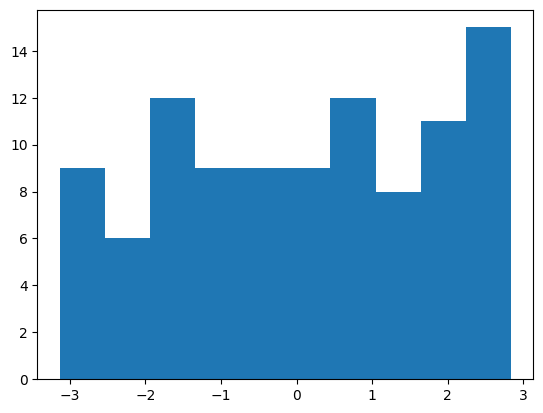

In [85]:
import matplotlib.pyplot as plt

plt.hist(turns)